# Wearable Human Activity Recognition (HAR) — Data Pipeline, EDA & Classic RNN Models
**Course:** AI 403 · Deep Learning Final Project · Faculty of Computer Science & AI, Pharos University  
**Dataset:** UCI Human Activity Recognition Using Smartphones (9 Inertial Sensor Channels, 50Hz, 128-Step Windows)

---
## Step 1: Environment & Library Setup
This cell imports the required scientific computing, visualization, and deep learning libraries (`TensorFlow / Keras`), sets a global random seed (`SEED = 42`) for reproducibility, and links the project root directory to load our custom data pipeline.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Add project root to system path to import our leakage-free loader
sys.path.append(os.path.abspath(".."))
from src.datasets.loader import get_har_data, _load_subjects, ACTIVITY_LABELS

keras.utils.set_random_seed(42)
print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


## Step 2: Leakage-Free Data Loading & Integrity Verification
In time-series HAR datasets, random window splitting causes **data leakage** because overlapping windows from the same person appear in both training and testing sets.  
Here, we load our subject-wise partitioned tensors (`17 Train Subjects`, `4 Validation Subjects`, and `9 Held-Out Test Subjects`), verify that there are zero missing (`NaN`) values and zero overlapping subjects, and confirm that Z-score standardization ($\mu=0, \sigma=1$) was computed strictly on the training set.

In [2]:
DATASET_PATH = "../data/UCI HAR Dataset"
_, _, _, raw_arrays, stats = get_har_data(dataset_path=DATASET_PATH)
X_train, y_train, X_val, y_val, X_test, y_test = raw_arrays

# Verify zero subject overlap and zero missing values
subj_train = _load_subjects(DATASET_PATH, "train")
subj_test = _load_subjects(DATASET_PATH, "test")

integrity_df = pd.DataFrame({
    "Verification Metric": [
        "Train Tensor Shape (Windows, Time Steps, Channels)",
        "Validation Tensor Shape (4 Held-Out Subjects)",
        "Test Tensor Shape (9 Held-Out Subjects)",
        "Missing / NaN Values Count",
        "Train vs. Test Subject Overlap",
        "Standardized Train Mean / Std"
    ],
    "Status / Value": [
        str(X_train.shape),
        str(X_val.shape),
        str(X_test.shape),
        str(np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum()),
        f"{len(np.intersect1d(subj_train, subj_test))} (Zero Leakage Verified)",
        f"{X_train.mean():.4f} / {X_train.std():.4f}"
    ]
})
display(integrity_df)

,Verification Metric,Status / Value
0,"Train Tensor Shape (Windows, Time Steps, Chann...","(6037, 128, 9)"
1,Validation Tensor Shape (4 Held-Out Subjects),"(1315, 128, 9)"
2,Test Tensor Shape (9 Held-Out Subjects),"(2947, 128, 9)"
3,Missing / NaN Values Count,0
4,Train vs. Test Subject Overlap,0 (Zero Leakage Verified)
5,Standardized Train Mean / Std,0.0000 / 1.0000


## Step 3: Exploratory Data Analysis (Class Balance & Sensor Signal Dynamics)
This cell generates **Table 1** (class distribution across Train, Validation, and Test splits) to check for class imbalance, alongside a side-by-side visualization comparing:
1. **Left:** Window counts per activity across all three subject-wise splits.
2. **Right:** Normalized `Body Acc X` signal waveforms contrasting a high-variance dynamic activity (`WALKING`) against a low-variance static posture (`LAYING`).

,Activity Class,Train (17 Subjects),Val (4 Subjects),Test (9 Subjects),Total Windows,Percentage (%)
0,WALKING,960,266,496,1722,16.72
1,WALKING_UPSTAIRS,863,210,471,1544,14.99
2,WALKING_DOWNSTAIRS,793,193,420,1406,13.65
3,SITTING,1088,198,491,1777,17.25
4,STANDING,1147,227,532,1906,18.51
5,LAYING,1186,221,537,1944,18.88


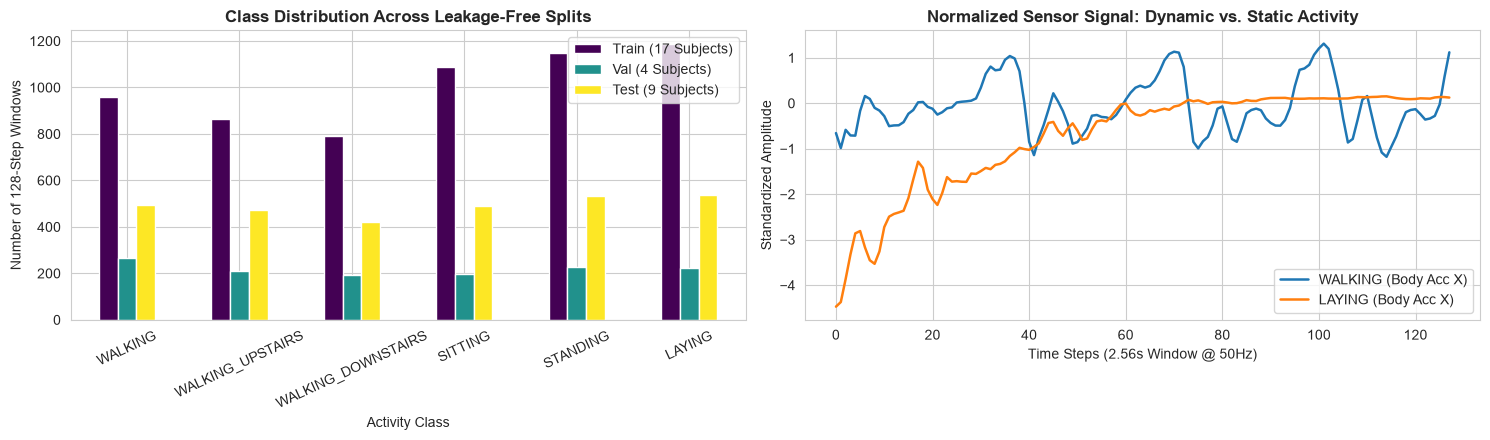

In [3]:
# Summary table of class counts across splits (Report Table 1)
dist_df = pd.DataFrame({
    "Activity Class": ACTIVITY_LABELS,
    "Train (17 Subjects)": [(y_train == i).sum() for i in range(6)],
    "Val (4 Subjects)": [(y_val == i).sum() for i in range(6)],
    "Test (9 Subjects)": [(y_test == i).sum() for i in range(6)],
})
dist_df["Total Windows"] = dist_df[["Train (17 Subjects)", "Val (4 Subjects)", "Test (9 Subjects)"]].sum(axis=1)
dist_df["Percentage (%)"] = (dist_df["Total Windows"] / dist_df["Total Windows"].sum() * 100).round(2)
display(dist_df)

# Visualize class balance and dynamic vs. static sensor signals
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

dist_df.set_index("Activity Class")[["Train (17 Subjects)", "Val (4 Subjects)", "Test (9 Subjects)"]].plot(
    kind="bar", ax=axes[0], colormap="viridis"
)
axes[0].set_title("Class Distribution Across Leakage-Free Splits", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of 128-Step Windows")
axes[0].tick_params(axis="x", rotation=25)

walk_idx = np.where(y_train == 0)[0][0]
lay_idx = np.where(y_train == 5)[0][0]
axes[1].plot(X_train[walk_idx, :, 0], label="WALKING (Body Acc X)", linewidth=1.8)
axes[1].plot(X_train[lay_idx, :, 0], label="LAYING (Body Acc X)", linewidth=1.8)
axes[1].set_title("Normalized Sensor Signal: Dynamic vs. Static Activity", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Time Steps (2.56s Window @ 50Hz)")
axes[1].set_ylabel("Standardized Amplitude")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Phase 2: Baseline Model (Non-Temporal Tabular Benchmark)
### Step 4: Training & Evaluating Random Forest across 3 Seeds
Before introducing recurrent neural networks, we establish a classical machine learning **Baseline** (`RandomForestClassifier` with 100 estimators) trained on flattened $128 \times 9$ sensor windows ($1,152$ features per window).  
Following our experimental protocol:
- Evaluated across **3 random seeds** (`42, 123, 2026`) to report **Mean ± SD** for Accuracy and Macro-F1.
- Logs training and per-window inference latency alongside a **Confusion Matrix** on the held-out Test set to diagnose which activities suffer without explicit sequence modeling.

,Model,Val Accuracy (%),Val Macro-F1 (%),Test Accuracy (%),Test Macro-F1 (%),Train Time (s),Inference (ms/win)
0,Baseline (Random Forest),92.95 ± 0.41,92.87 ± 0.40,83.49 ± 0.40,83.26 ± 0.43,1.56,0.0133


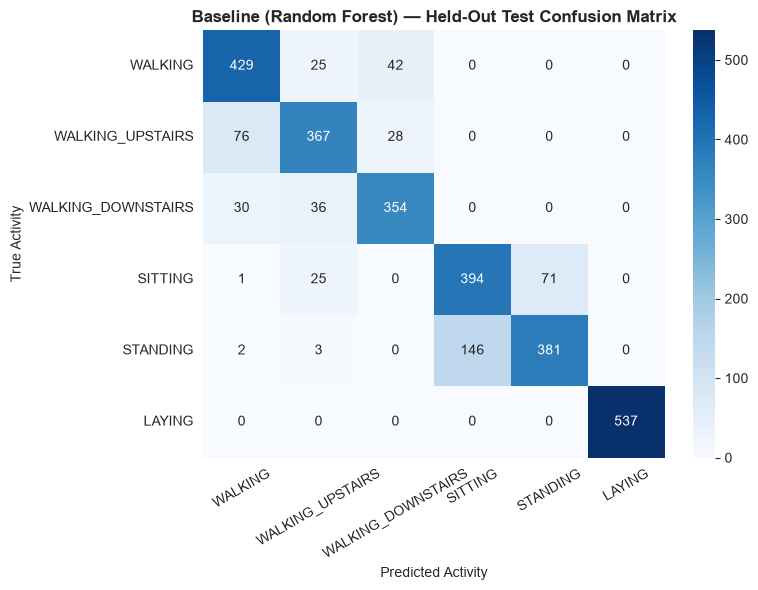

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Flatten 3D windows (Samples, 128, 9) into 2D feature vectors (Samples, 1152)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

SEEDS = [42, 123, 2026]
val_accs, val_f1s = [], []
test_accs, test_f1s = [], []
train_times, infer_times = [], []

for seed in SEEDS:
    rf_model = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)
    
    # Measure training time
    t0 = time.time()
    rf_model.fit(X_train_flat, y_train)
    train_times.append(time.time() - t0)
    
    # Validation evaluation
    val_preds = rf_model.predict(X_val_flat)
    val_accs.append(accuracy_score(y_val, val_preds) * 100)
    val_f1s.append(f1_score(y_val, val_preds, average="macro") * 100)
    
    # Measure test inference latency & evaluate
    t1 = time.time()
    test_preds = rf_model.predict(X_test_flat)
    infer_times.append((time.time() - t1) / len(X_test) * 1000) # ms per window
    
    test_accs.append(accuracy_score(y_test, test_preds) * 100)
    test_f1s.append(f1_score(y_test, test_preds, average="macro") * 100)

# Summary table (Report Table 2 & Table 7)
baseline_summary = pd.DataFrame({
    "Model": ["Baseline (Random Forest)"],
    "Val Accuracy (%)": [f"{np.mean(val_accs):.2f} ± {np.std(val_accs):.2f}"],
    "Val Macro-F1 (%)": [f"{np.mean(val_f1s):.2f} ± {np.std(val_f1s):.2f}"],
    "Test Accuracy (%)": [f"{np.mean(test_accs):.2f} ± {np.std(test_accs):.2f}"],
    "Test Macro-F1 (%)": [f"{np.mean(test_f1s):.2f} ± {np.std(test_f1s):.2f}"],
    "Train Time (s)": [f"{np.mean(train_times):.2f}"],
    "Inference (ms/win)": [f"{np.mean(infer_times):.4f}"]
})
display(baseline_summary)

# Plot Confusion Matrix on Held-Out Test Set (Seed 2026)
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ACTIVITY_LABELS, yticklabels=ACTIVITY_LABELS)
plt.title("Baseline (Random Forest) — Held-Out Test Confusion Matrix", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

---
## Phase 3: Deep Learning Sequence Model (Bidirectional LSTM)
### Step 5: Training & Evaluating the Bidirectional LSTM Model (3 Seeds)
To capture temporal dependencies that the tabular Random Forest baseline misses, we implement a clean, single-layer **Bidirectional LSTM** (`units=64` per direction $\rightarrow 128$ concatenated temporal features) across the 128-step movement window:
- **Architecture:** `Input(128, 9)` $\rightarrow$ `Bidirectional(LSTM(64, dropout=0.2))` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Dense(6, softmax)`.
- **Optimization & Regularization:** Trained with `Adam(learning_rate=1e-3, clipnorm=1.0)` and `EarlyStopping(patience=8, restore_best_weights=True)` across **3 random seeds** (`42, 123, 2026`).

Model: "Single_Layer_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │        37,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,662 (151.02 KB)

 Trainable params: 38,662 (151.02 KB)

 Non-trainable params: 0 (0.00 B)


🚀 Training Bi-LSTM (Seed = 42)...
Epoch 1/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.6150 - loss: 1.0093 - val_accuracy: 0.8319 - val_loss: 0.5548
Epoch 2/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.8300 - loss: 0.4487 - val_accuracy: 0.9232 - val_loss: 0.2290
Epoch 3/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8951 - loss: 0.2830 - val_accuracy: 0.9399 - val_loss: 0.1350
Epoch 4/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9127 - loss: 0.2295 - val_accuracy: 0.9430 - val_loss: 0.1325
Epoch 5/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9230 - loss: 0.1981 - val_accuracy: 0.9316 - val_loss: 0.1278
Epoch 6/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9178 - loss: 0.2017 - val_accuracy: 0.9156 - val_loss: 0.2116
Epoch 7/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9216 - loss: 0.2024 - val_accuracy: 0.9338 - val_loss: 0.1543
Epoch 8/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9221 - loss

,Model,Val Accuracy (%),Val Macro-F1 (%),Test Accuracy (%),Test Macro-F1 (%),Train Time (s),Inference (ms/win)
0,Baseline (Random Forest),92.95 ± 0.41,92.87 ± 0.40,83.49 ± 0.40,83.26 ± 0.43,1.56,0.0133
1,"Classic Bi-LSTM (38,662 params)",94.20 ± 0.75,94.06 ± 0.77,91.23 ± 0.98,91.36 ± 0.99,76.43,0.3617


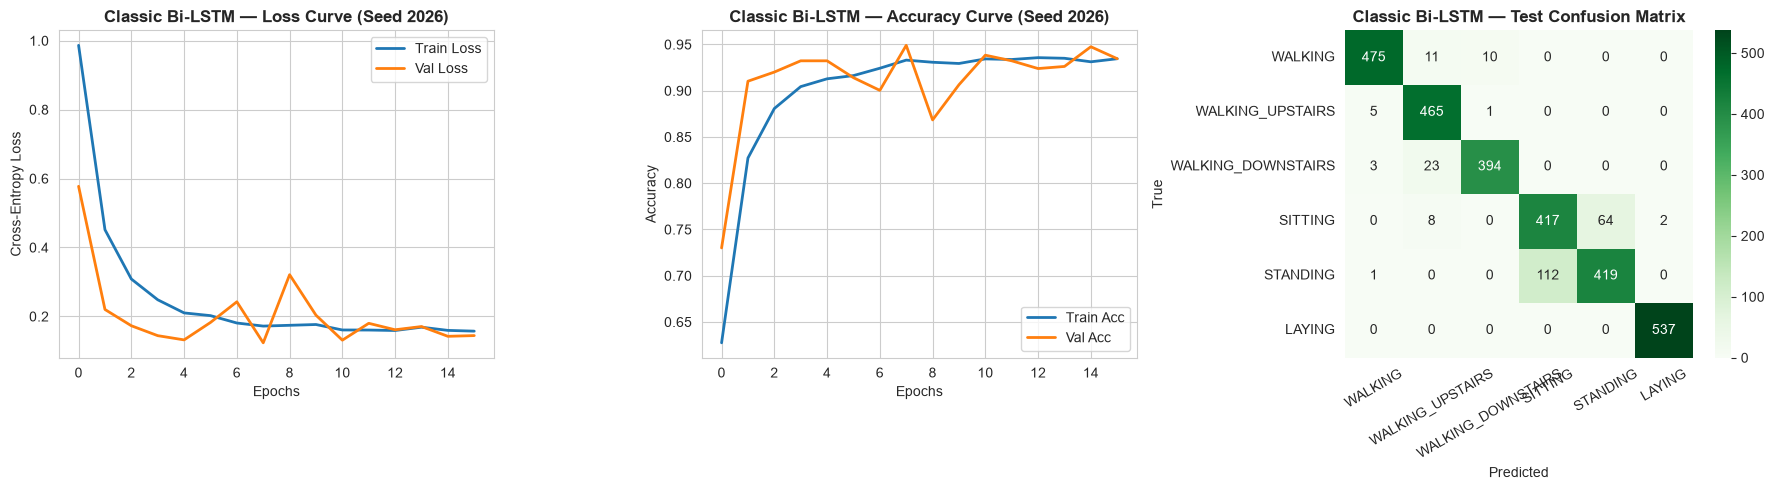

In [6]:
def build_bilstm(input_shape=(128, 9), num_classes=6, units=64):
    """Build a clean single-layer Bidirectional LSTM classifier."""
    inputs = layers.Input(shape=input_shape)
    
    # Single Bidirectional LSTM layer (64 forward + 64 backward = 128 features)
    x = layers.Bidirectional(layers.LSTM(units, dropout=0.2))(inputs)
    
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    
    model = keras.Model(inputs, outputs, name="Single_Layer_BiLSTM")
    optimizer = keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# Print model summary once
sample_model = build_bilstm()
sample_model.summary()
total_params = sample_model.count_params()

# Train & evaluate across 3 seeds
bilstm_val_accs, bilstm_val_f1s = [], []
bilstm_test_accs, bilstm_test_f1s = [], []
bilstm_train_times, bilstm_infer_times = [], []
last_history = None
last_test_preds = None

for seed in SEEDS:
    print(f"\n🚀 Training Bi-LSTM (Seed = {seed})...")
    keras.utils.set_random_seed(seed)
    model = build_bilstm()
    
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
    )
    
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )
    bilstm_train_times.append(time.time() - t0)
    last_history = history
    
    # Validation predictions
    val_preds = np.argmax(model.predict(X_val, verbose=0), axis=1)
    bilstm_val_accs.append(accuracy_score(y_val, val_preds) * 100)
    bilstm_val_f1s.append(f1_score(y_val, val_preds, average="macro") * 100)
    
    # Test predictions & inference latency
    t1 = time.time()
    test_probs = model.predict(X_test, verbose=0)
    bilstm_infer_times.append((time.time() - t1) / len(X_test) * 1000)
    
    test_preds = np.argmax(test_probs, axis=1)
    last_test_preds = test_preds
    bilstm_test_accs.append(accuracy_score(y_test, test_preds) * 100)
    bilstm_test_f1s.append(f1_score(y_test, test_preds, average="macro") * 100)

# Compare Baseline vs. Bi-LSTM (Report Table 2 & Table 7)
bilstm_row = pd.DataFrame({
    "Model": [f"Classic Bi-LSTM ({total_params:,} params)"],
    "Val Accuracy (%)": [f"{np.mean(bilstm_val_accs):.2f} ± {np.std(bilstm_val_accs):.2f}"],
    "Val Macro-F1 (%)": [f"{np.mean(bilstm_val_f1s):.2f} ± {np.std(bilstm_val_f1s):.2f}"],
    "Test Accuracy (%)": [f"{np.mean(bilstm_test_accs):.2f} ± {np.std(bilstm_test_accs):.2f}"],
    "Test Macro-F1 (%)": [f"{np.mean(bilstm_test_f1s):.2f} ± {np.std(bilstm_test_f1s):.2f}"],
    "Train Time (s)": [f"{np.mean(bilstm_train_times):.2f}"],
    "Inference (ms/win)": [f"{np.mean(bilstm_infer_times):.4f}"]
})

comparison_df = pd.concat([baseline_summary, bilstm_row], ignore_index=True)
display(comparison_df)

# Plot Learning Curves + Test Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(last_history.history["loss"], label="Train Loss", linewidth=2)
axes[0].plot(last_history.history["val_loss"], label="Val Loss", linewidth=2)
axes[0].set_title("Classic Bi-LSTM — Loss Curve (Seed 2026)", fontweight="bold")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(last_history.history["accuracy"], label="Train Acc", linewidth=2)
axes[1].plot(last_history.history["val_accuracy"], label="Val Acc", linewidth=2)
axes[1].set_title("Classic Bi-LSTM — Accuracy Curve (Seed 2026)", fontweight="bold")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

cm_bilstm = confusion_matrix(y_test, last_test_preds)
sns.heatmap(cm_bilstm, annot=True, fmt="d", cmap="Greens", xticklabels=ACTIVITY_LABELS, yticklabels=ACTIVITY_LABELS, ax=axes[2])
axes[2].set_title("Classic Bi-LSTM — Test Confusion Matrix", fontweight="bold")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("True")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

---
## Phase 4: Exporting Model & Benchmark Results
### Step 6: Saving the Trained Bi-LSTM Model & Summary Metrics
We export the trained `Bi-LSTM` model weights (`saved_models/bilstm_har.keras`) and save the multi-seed evaluation table (`results/baseline_bilstm_metrics.csv`) for downstream error analysis, report compilation, and deployment.

In [7]:
from sklearn.metrics import classification_report

# Create output directories if they do not exist
os.makedirs("../saved_models", exist_ok=True)
os.makedirs("../results", exist_ok=True)

# 1. Save trained Keras model and comparison metrics table
model.save("../saved_models/bilstm_har.keras")
comparison_df.to_csv("../results/baseline_bilstm_metrics.csv", index=False)

print("✅ Model saved to: saved_models/bilstm_har.keras")
print("✅ Metrics saved to: results/baseline_bilstm_metrics.csv\n")

# 2. Print detailed per-class Precision, Recall, and F1-Score on Test set
print("=== Per-Class Classification Report (Test Set) ===")
print(classification_report(y_test, last_test_preds, target_names=ACTIVITY_LABELS, digits=4))

✅ Model saved to: saved_models/bilstm_har.keras
✅ Metrics saved to: results/baseline_bilstm_metrics.csv

=== Per-Class Classification Report (Test Set) ===
                    precision    recall  f1-score   support

           WALKING     0.9814    0.9577    0.9694       496
  WALKING_UPSTAIRS     0.9172    0.9873    0.9509       471
WALKING_DOWNSTAIRS     0.9728    0.9381    0.9552       420
           SITTING     0.7883    0.8493    0.8176       491
          STANDING     0.8675    0.7876    0.8256       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9186      2947
         macro avg     0.9206    0.9200    0.9195      2947
      weighted avg     0.9199    0.9186    0.9184      2947

